In [2]:
import pandas as pd

df = pd.read_csv("../data/train.csv")

df.head()


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [3]:
features = [
    "Support Calls",
    "Payment Delay",
    "Total Spend",
    "Last Interaction"
]

target = "Churn"

In [4]:
correlations = (
    df[features + [target]]
    .corr()[target]
    .sort_values(ascending=False)
)

correlations

Churn               1.000000
Support Calls       0.574267
Payment Delay       0.312129
Last Interaction    0.149616
Total Spend        -0.429355
Name: Churn, dtype: float64

In [14]:
X = df[
    [
        "Support Calls",
        "Payment Delay",
        "Total Spend",
        "Last Interaction"
    ]
]

y = df["Churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (440832, 4)
y shape: (440832,)


,Support Calls,Payment Delay,Total Spend,Last Interaction
0,5.0,18.0,932.0,17.0
1,10.0,8.0,557.0,6.0
2,6.0,18.0,185.0,3.0
3,7.0,7.0,396.0,29.0
4,5.0,8.0,617.0,20.0


In [15]:
print(y.value_counts())

print("\nPercentage:")
print((y.value_counts(normalize=True) * 100).round(2))

Churn
1.0    249999
0.0    190833
Name: count, dtype: int64

Percentage:
Churn
1.0    56.71
0.0    43.29
Name: proportion, dtype: float64


In [16]:
df = df.dropna().reset_index(drop=True)

print(df.shape)
print(df.isnull().sum())

(440832, 12)
CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64


In [11]:
print("df shape:", df.shape)
print("NaNs in Churn:", df["Churn"].isna().sum())
print("NaNs in X:", X.isna().sum().sum())
print("NaNs in y:", y.isna().sum())

print("\nRows with missing Churn:")
display(df[df["Churn"].isna()])

df shape: (440832, 12)
NaNs in Churn: 0
NaNs in X: 4
NaNs in y: 1

Rows with missing Churn:


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn


In [12]:
df = df.dropna(subset=["Churn"]).copy()
df = df.reset_index(drop=True)

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (352665, 4)
Testing: (88167, 4)


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [20]:
print("Original:")
print(X_train.iloc[0])

print("\nScaled:")
print(X_train_scaled[0])

Original:
Support Calls         3.00
Payment Delay         4.00
Total Spend         945.08
Last Interaction      8.00
Name: 318330, dtype: float64

Scaled:
[-0.19715605 -1.08532001  1.30095567 -0.75344945]


In [21]:
import torch

X_train_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

y_test_tensor = torch.tensor(
    y_test.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

In [22]:
import torch.nn as nn

In [25]:
import torch.nn as nn

class ChurnNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Layers
        self.layer1 = nn.Linear(4, 8)
        self.layer2 = nn.Linear(8, 4)
        self.output = nn.Linear(4, 1)

        # Activation functions
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        x = self.layer1(x)
        x = self.relu(x)

        x = self.layer2(x)
        x = self.relu(x)

        x = self.output(x)
        x = self.sigmoid(x)

        return x

In [26]:
model = ChurnNN()

print(model)

ChurnNN(
  (layer1): Linear(in_features=4, out_features=8, bias=True)
  (layer2): Linear(in_features=8, out_features=4, bias=True)
  (output): Linear(in_features=4, out_features=1, bias=True)
  (relu): ReLU()
  (sigmoid): Sigmoid()
)


In [27]:
criterion = nn.BCELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [28]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

In [29]:
epochs = 20

In [30]:
loss_history = []

for epoch in range(epochs):

    total_loss = 0

    for X_batch, y_batch in train_loader:

        # 1. Forward propagation
        predictions = model(X_batch)

        # 2. Calculate loss
        loss = criterion(predictions, y_batch)

        # 3. Clear old gradients
        optimizer.zero_grad()

        # 4. Backpropagation
        loss.backward()

        # 5. Update weights
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    loss_history.append(average_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} "
        f"- Loss: {average_loss:.4f}"
    )

Epoch 1/20 - Loss: 0.2565
Epoch 2/20 - Loss: 0.2176
Epoch 3/20 - Loss: 0.2144
Epoch 4/20 - Loss: 0.2135
Epoch 5/20 - Loss: 0.2131
Epoch 6/20 - Loss: 0.2128
Epoch 7/20 - Loss: 0.2124
Epoch 8/20 - Loss: 0.2122
Epoch 9/20 - Loss: 0.2120
Epoch 10/20 - Loss: 0.2118
Epoch 11/20 - Loss: 0.2116
Epoch 12/20 - Loss: 0.2115
Epoch 13/20 - Loss: 0.2114
Epoch 14/20 - Loss: 0.2113
Epoch 15/20 - Loss: 0.2113
Epoch 16/20 - Loss: 0.2113
Epoch 17/20 - Loss: 0.2113
Epoch 18/20 - Loss: 0.2112
Epoch 19/20 - Loss: 0.2112
Epoch 20/20 - Loss: 0.2112


In [35]:
loss_history.append(average_loss)

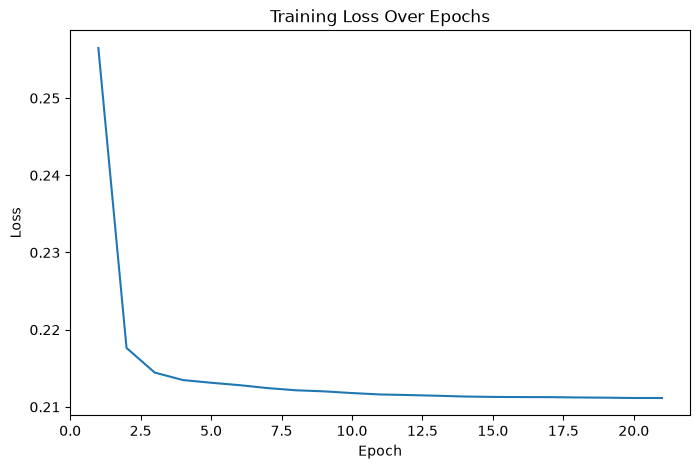

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(loss_history) + 1),
    loss_history
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")

plt.show()